<a href="https://colab.research.google.com/github/azizbekreimbaev/cv/blob/main/menu_detector_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [50]:
print("Menu detector")

Menu detector


In [51]:
from google.colab import drive
import torchvision.transforms as transforms
from torchvision import transforms

from PIL import Image, UnidentifiedImageError
from torch.utils.data import Dataset, DataLoader

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision.models import mobilenet_v2

import os
import numpy as np

In [52]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [53]:
DATASET_PATH = '/content/drive/MyDrive/food_dataset'


In [54]:
CUSTOM_CLASS_MAPPING = {
    "hamburger":"hamburger",
    "hot_dog": "hot_dog",
    "pizza": "pizza",
    "chocolate_cake": "dessert", #label grouping | class consolidation
    "cheesecake": "dessert", #label grouping | class consolidation
}

CLASSES = ['hamburger', 'hot_dog', 'dessert', 'pizza']
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)


print(CLASS_TO_IDX)

#TRANSFORM compose method(is like pipeline) helps to transform by order

transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])





{'hamburger': 0, 'hot_dog': 1, 'dessert': 2, 'pizza': 3}


Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

In [55]:

# =========================
# Custom Dataset Class
# =========================

class FoodDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        # print('images_length', len(self.images))
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        # print('image_path', img_path)

        label = self.labels[idx]
        # print('label', label)

        try:
            image = Image.open(img_path)
            if image.mode == "P" or image.mode == "RGBA":
              image = image.convert("RGBA").convert("RGB")
            else:
              image = image.convert("RGB")
        except (UnidentifiedImageError, OSError):
            print(f"Skipping broken image: {img_path}")
            return self.__getitem__((idx + 1) % len(self.images))

        if self.transform:
            image = self.transform(image)

        return image, label

In [56]:
# =========================
# Gather and Split Data
# =========================

all_images = []

for original_class, mapped_class in CUSTOM_CLASS_MAPPING.items():
    class_path = os.path.join(DATASET_PATH, original_class)  # /content/drive/MyDrive/food101_dataset
    print('class_path:', class_path)

    if not os.path.exists(class_path):
        print(f"Warning: {class_path} not found")
        continue

    for img in os.listdir(class_path):
        if img.endswith(('.jpg', '.jpeg', '.png')):
            full_path = os.path.join(class_path, img)
            all_images.append((full_path, CLASS_TO_IDX[mapped_class]))

np.random.shuffle(all_images)

split = int(0.8 * len(all_images))

train_data = all_images[:split]
val_data = all_images[split:]

train_images, train_labels = zip(*train_data)
val_images, val_labels = zip(*val_data)

# print('all_images:', all_images)

dataset = FoodDataset(train_images, train_labels)

print(len(dataset))

img, lbl = dataset[0]

class_path: /content/drive/MyDrive/food_dataset/hamburger
class_path: /content/drive/MyDrive/food_dataset/hot_dog
class_path: /content/drive/MyDrive/food_dataset/pizza
class_path: /content/drive/MyDrive/food_dataset/chocolate_cake
class_path: /content/drive/MyDrive/food_dataset/cheesecake
4000


In [57]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("transform:", "transform" in globals())
print(transform)

transform: True
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [58]:
train_dataset = FoodDataset(train_images, train_labels, transform=transform)
val_dataset = FoodDataset(val_images, val_labels, transform=transform)


In [59]:
print("transform:", "transform" in globals())
print("FoodDataset:", "FoodDataset" in globals())
print("train_images:", "train_images" in globals())
print("train_labels:", "train_labels" in globals())

transform: True
FoodDataset: True
train_images: True
train_labels: True


In [60]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)  # Parallel loading for speed

val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)


In [61]:
# =========================
# Pretrained Model
# =========================

model = mobilenet_v2(weights="IMAGENET1K_V1")

# Replace final classification layer
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    NUM_CLASSES
)

In [62]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device', device)
model = model.to(device)

device cuda


In [63]:
criterion = nn.CrossEntropyLoss() #Loss function

optimizer = optim.Adam(model.parameters(), lr=0.001)
torch.backends.cudnn.benchmark = True

In [64]:
NUM_EPOCHS = 10
best_accuracy = 0.0

for epoch in range(NUM_EPOCHS):
    model.train()  # Train mode
    running_loss = 0.0

    # Training - Forward and Backward (Backpropagation)
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()  # Zero the gradients

        outputs = model(images)  # Forward Pass
        loss = criterion(outputs, labels)  # Calculate Loss

        loss.backward()  # Backpropagation
        optimizer.step()  # Update weights using Adam

        running_loss += loss.item()  # Track Loss

    # =========================
    # Validation
    # =========================

    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_acc = 100 * correct / total #Calculate accuracy of validation (tesdting step)

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
        f"Loss: {running_loss/len(train_loader):.4f}, "
        f"Val Accuracy: {val_acc:.2f}%"
    )

    # Save best model
    if val_acc > best_accuracy:
        best_accuracy = val_acc

        torch.save(
            model.state_dict(),
            '/content/menu_detector.pth'
        )

        print("Saved new best model!")

Epoch [1/10] Loss: 0.5455, Val Accuracy: 86.40%
Saved new best model!
Epoch [2/10] Loss: 0.3192, Val Accuracy: 89.00%
Saved new best model!
Epoch [3/10] Loss: 0.2533, Val Accuracy: 91.50%
Saved new best model!
Epoch [4/10] Loss: 0.2209, Val Accuracy: 89.40%
Epoch [5/10] Loss: 0.1730, Val Accuracy: 88.80%
Epoch [6/10] Loss: 0.1940, Val Accuracy: 86.70%
Epoch [7/10] Loss: 0.1413, Val Accuracy: 91.00%
Epoch [8/10] Loss: 0.1311, Val Accuracy: 89.20%
Epoch [9/10] Loss: 0.1180, Val Accuracy: 91.80%
Saved new best model!
Epoch [10/10] Loss: 0.0831, Val Accuracy: 86.90%


Menu Detector Model Usage

device: cuda
Upload one or more images of your food:


Saving cake3.jpg to cake3.jpg


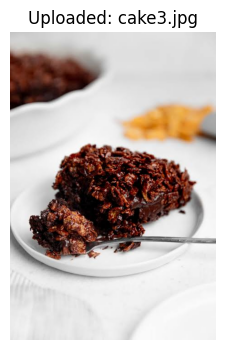

Prediction:
  ✅ dessert: 99.99%
  ✅ hamburger: 0.01%
  ✅ hot_dog: 0.00%
  ✅ pizza: 0.00%


In [72]:
# ==========================================
# Required Imports
# ==========================================

import torch
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2
from PIL import Image
from google.colab import files
import io
import matplotlib.pyplot as plt


# ==========================================
# Define Semantic Classes
# ==========================================

CLASSES = ['hamburger', 'hot_dog', 'dessert', 'pizza']  # Must match training order

NUM_CLASSES = len(CLASSES)

CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}


# ==========================================
# Transform for Uploaded Images
# (No augmentations!)
# ==========================================

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ==========================================
# Load Model
# ==========================================

model = mobilenet_v2(weights=None)

model.classifier[1] = torch.nn.Linear(
    model.classifier[1].in_features,
    NUM_CLASSES
)

model.load_state_dict(
    torch.load(
        '/content/menu_detector.pth',
        map_location='cpu',
        weights_only=True
    )
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('device:', device)

model = model.to(device)

model.eval()

# ==========================================
# Upload & Predict
# ==========================================

print("Upload one or more images of your food:")
uploaded = files.upload()

for image_name in uploaded.keys():
    image = Image.open(
        io.BytesIO(uploaded[image_name])
    ).convert('RGB')

    # Display image
    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis('off')
    plt.title(f'Uploaded: {image_name}')
    plt.show()

    # Predict
    image_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image_tensor)
        probs = torch.softmax(output, dim=1)[0]
        topk = torch.topk(probs, min(4, len(CLASSES)))

    print("Prediction:")

    for i in range(topk.indices.size(0)):
        label = CLASSES[topk.indices[i].item()]
        confidence = topk.values[i].item() * 100

        print(f"  ✅ {label}: {confidence:.2f}%")